# Maxwell 3D directional coupler
Two single-mode silicon waveguides run side by side with a sub-wavelength gap.
The evanescent tail of the mode in one guide reaches into the other, so power
leaks across and sloshes back and forth along the device -- the basis of every
directional-coupler splitter, switch, and ring-bus coupler in integrated optics.

This is a genuine 3D structure: two 450 x 220 nm silicon cores embedded in SiO2,
with real material indices. The simulation axes are
  * x = propagation along the chip,
  * y = lateral (across the two guides, the WIDTH direction),
  * z = vertical (the 220 nm core-thickness direction).

The coupling is set by the beat between the two *supermodes* of the pair (the
even/symmetric and odd/antisymmetric combinations): light launched in one guide
transfers completely to the other over the coupling length
``L_c = pi / (beta_sym - beta_antisym)``, then returns, with period ``2 L_c``.

Why a full-wave solver: evanescent coupling is a near-field overlap of
exponential mode tails across the gap -- no ray-optics picture of light "jumping"
between guides. The transfer length depends on the small phase difference the two
supermodes accumulate along the device.

The device is laid out for a coupling length given as a design input; the run
measures the one the field actually shows, and predicts it from the two supermodes
the engine solves. Light in one guide alone is the sum of the symmetric and the
antisymmetric supermode with equal amplitude, so the launch is two mode sources on
the same cut: the engine solves the pair's modes on the (y, z) cross-section of the
simulation grid when the run starts, with its pseudo-spectral mode solver, and drives
both one way along the guides. Where they are in phase the light sits in the first guide;
where they are in antiphase it has crossed to the second. Quasi-TE polarization (dominant
E along the width, y).

The guides are drawn as staircase boxes whose faces lie on voxel faces. Nothing changes
along x, so the grid is four times coarser along it than across the guides.

Size: 37.16 Mvoxel including boundaries, 1.94 GB of memory (service estimate).

In [1]:
import numpy as np
from scipy.optimize import curve_fit

from wavesimpro import Box, Medium, Setup, create_mode_source, create_monitor, submit
from wsutils import output_dir

NAME = "mx_directional_coupler"   # run name on the service and output folder
OUTPUT_DIR = output_dir(NAME)   # <repo root>/output/<NAME>

### Parameters (edit these to rescale)

In [2]:
wavelength = 1.55  # design wavelength in micrometer (μm)
# Grid pitch (dx, dy, dz) in μm. The pitches across the guides divide the cross-section
# exactly: 18 px in the 450 nm width, 8 px in the gap, 10 px in the 220 nm core.
pixel_size = [0.1, 0.025, 0.022]
dx, dy, dz = pixel_size

n_si = 3.476   # silicon core
n_clad = 1.444  # SiO2 cladding

t_core = 0.22  # Si core thickness, vertical z (μm)
w_wg = 0.45    # single-mode waveguide width, lateral y (μm)
gap = 0.20     # edge-to-edge gap between the two guides (μm) -> strong coupling

L_c_design = 24.15        # coupling length the device is laid out for (μm)
n_coupling_lengths = 2.0  # device length in units of L_c (2 -> one full crossover and back)

sim_y = 4.0    # lateral domain (μm)
sim_z = t_core + 2.42  # vertical domain: core + oxide margin (μm), a whole even number of voxels
yc = sim_y / 2
sep = (w_wg + gap) / 2  # center-to-center half-separation
y_top = yc - sep  # upper guide center (the launch guide)
y_bot = yc + sep  # lower guide center

# Each supermode is launched one way by driving a length of guide with its own phase,
# so the backward waves cancel. The drive is centred on x_source. Two straight guides
# scatter almost nothing, so the launch is the only thing lighting the cladding here.
x_source = 2.5       # centre of the driven length (μm)
drive_length = 3.0   # μm of guide driven

# Absorbing boundary, per axis: padding is added to every face, so size each one by the
# power that reaches it. The guided modes exit through x carrying everything; y and z see
# only evanescent tail and weak radiation.
boundary_widths = [4.0 * wavelength, 1.0 * wavelength, 0.5 * wavelength]

coupling_length = n_coupling_lengths * L_c_design
sim_x = x_source + coupling_length + 3.0
nx = int(round(sim_x / dx))
ny = int(round(sim_y / dy))
nz = int(round(sim_z / dz))
print(f"Device {coupling_length:.1f} um for L_c = {L_c_design} um; domain {sim_x:.1f} um long")

Device 48.3 um for L_c = 24.15 um; domain 53.8 um long


### Build the 3D geometry: two parallel guides across the whole domain

In [3]:
# Box positions are in coordinates centred on the domain. The strips run on through the
# x absorbers, so the guided light leaves the domain without meeting an end facet.
size_x, size_y, size_z = nx * dx, ny * dy, nz * dz
strip_length = size_x + 2 * boundary_widths[0] + 2.0
silicon = Medium("Si", n_si)
strips = [Box(n=silicon, name=name, center=(0.0, y_center - size_y / 2, 0.0),
              size=(strip_length, w_wg, t_core), subpixel=False)
          for name, y_center in (("guide_top", y_top), ("guide_bottom", y_bot))]
mvox = nx * ny * nz / 1e6
print(f"Interior grid: {nx} x {ny} x {nz} = {mvox:.1f} Mvoxel  (pitch {pixel_size} um)")

Interior grid: 538 x 160 x 120 = 10.3 Mvoxel  (pitch [0.1, 0.025, 0.022] um)


### Source: the two supermodes, solved and launched by the engine

In [4]:
# The cut is the (y, z) layer where the drive ends. At run start the engine solves the
# full-vector modes of that layer of the permittivity the boxes produce; among the
# quasi-TE ones (E along y) order 0 is the symmetric supermode and order 1 the
# antisymmetric one. Both are driven over ``drive_length`` of guide ending at the cut, with
# equal amplitude and phase zero there, which puts all the light in the top guide at the cut.
i_drive_end = int(round((x_source + drive_length / 2) / dx))
sources = [create_mode_source(name=name, axis="x", plane_index=i_drive_end, direction=+1,
                              polarization="TE", order=order, drive_length_um=drive_length,
                              engine_solver="ps_operator")
           for name, order in (("symmetric", 0), ("antisymmetric", 1))]
launch_end = i_drive_end * dx
print(f"Mode sources: symmetric + antisymmetric supermodes, {drive_length} um driven towards "
      f"+x, ending at x = {launch_end:.2f} um")

y = np.arange(ny) * dy

Mode sources: symmetric + antisymmetric supermodes, 3.0 um driven towards +x, ending at x = 4.00 um


### Monitor: return just the x-y cut-plane this figure plots

In [5]:
# A monitor crops the result to this plane server-side, so only a thin slice is
# transferred instead of the full volume: a slab three voxels thick, centred on the voxel
# just above mid core height. Voxel index i on an n-voxel axis sits at (i + 0.5 - n/2) * pitch in
# domain-centred coordinates.
z_mid = nz // 2
z_world = (z_mid + 0.5 - nz / 2) * dz
monitor = create_monitor(
    name="cutplane",
    center_x=0.0, center_y=0.0, center_z=z_world,
    size_x=size_x, size_y=size_y, size_z=3 * dz,
)

### Run: submit the setup, read the monitor and the solved modes

In [6]:
# A setup is one document: the domain and grid, the cladding as background, the strips,
# the sources and the monitor. ``submit`` checks it, saves it on a new project and starts
# the run.
setup = Setup(wavelength, pixel_size, (nx, ny, nz), boundary_widths=boundary_widths,
              background=Medium("SiO2", n_clad), name=NAME)
setup.add(*strips, *sources, monitor)

for strip in strips:
    print(f"  {strip.name}: centre y = {strip.center[1]:+.4f} um, z = {strip.center[2]:+.4f} um; "
          f"{strip.size[1]} x {strip.size[2]} um")
print(f"  monitor: z = {z_world:+.4f} um, {size_x:.2f} x {size_y:.2f} um, 3 voxels thick")

run = submit(setup, sampling_warnings=False).wait()   # x is coarse on purpose
print(f"Time {run.elapsed:.1f} s; Iterations {run.iterations}; Residual {run.residual_norm}")

u = run.get_monitors()[0]

# The engine's record of the two supermodes it solved: their effective indices give the
# coupling length coupled-mode theory predicts for this cross-section. The pseudo-spectral
# mode solver discretizes the cross-section as the field solve does, so the field fit below
# should return the same length.
launched = {m["name"]: m["neff"]["re"] for m in run.mode_sources()}
neff_sym, neff_anti = launched["symmetric"], launched["antisymmetric"]
L_c_supermodes = wavelength / (2 * (neff_sym - neff_anti))
print(f"Supermodes solved by the engine: neff_sym = {neff_sym:.4f}, neff_anti = {neff_anti:.4f}")
print(f"  coupling length they predict: L_c = {L_c_supermodes:.2f} um")

# Ey on the x-y plane at the monitor's middle voxel, inside the core.
ey = u[1]
field_top = ey[:, :, ey.shape[2] // 2]

intensity = np.abs(field_top) ** 2
# x axis sized from the monitor's returned length.
x =np.arange(intensity.shape[0]) * dx
top_band = np.abs(y - y_top) < (w_wg / 2 + gap / 2)
bot_band = np.abs(y - y_bot) < (w_wg / 2 + gap / 2)
p_top = intensity[:, top_band].sum(axis=1)
p_bot = intensity[:, bot_band].sum(axis=1)

  [!] Mode source 'symmetric': linear absorbing layers at the two x ends (62 and 62 px) reflect a launched guided mode by about c_m / (W + 0.66), c_m a property of the mode (the engine reports it in the run notes); for 1e-3 that takes hundreds of pixels. boundary_profile='cubic' needs 47 px (4.75 um) per end.
  [!] Mode source 'antisymmetric': linear absorbing layers at the two x ends (62 and 62 px) reflect a launched guided mode by about c_m / (W + 0.66), c_m a property of the mode (the engine reports it in the run notes); for 1e-3 that takes hundreds of pixels. boundary_profile='cubic' needs 47 px (4.75 um) per end.


  guide_top: centre y = -0.3250 um, z = +0.0000 um; 0.45 x 0.22 um
  guide_bottom: centre y = +0.3250 um, z = +0.0000 um; 0.45 x 0.22 um
  monitor: z = +0.0110 um, 53.80 x 4.00 um, 3 voxels thick

  ------------------------------------------------------
  Rayfos remote simulation
  ------------------------------------------------------
  Project   : 65e54823-f638-4a8b-9aa1-583d2399df0c
  Version   : c6898b42-fee6-445d-b277-6ddbfe1ddd07
  Command   : eedb2602-3dfd-4cdb-bf30-d43317659fb6
  Mode      : Maxwell (vectorial)
  Domain    : 538x160x120 voxels  lambda=1.55 um  dx=(0.1, 0.025, 0.022) um
  Engine    : Any (auto-select)  |  GPU: auto
  Threshold : 1.0e-06  max iter: 100000
  ------------------------------------------------------
Time 106.0 s; Iterations 704; Residual 9.760861e-07
Supermodes solved by the engine: neff_sym = 2.3758, neff_anti = 2.3437
  coupling length they predict: L_c = 24.14 um


### What the run gives against what the supermodes predict

Coupling length: 24.15 um designed, 24.14 um from the solved supermodes, 24.15 +/- 0.00 um measured (-0.0% prediction error)
  peak transfer into the second guide: 97.2%


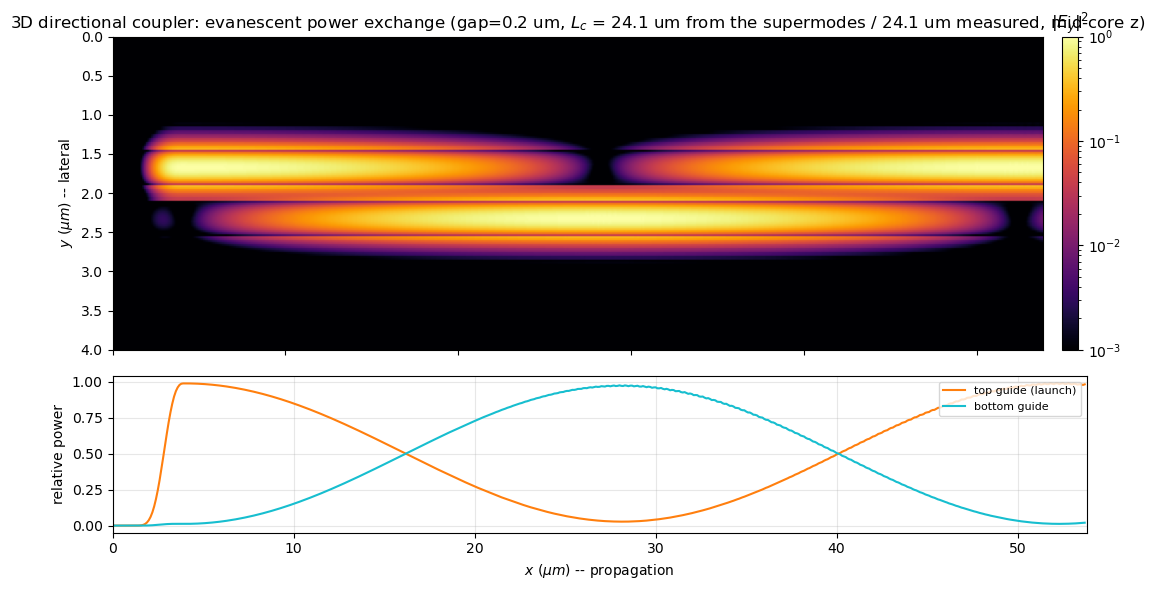

In [7]:
# A two-supermode beat puts the fraction in the second guide at sin^2(pi*(x - x0) / (2*L_c)),
# so fitting the whole curve reads the coupling length back out of the field. Using every
# point rather than the position of one extremum makes it precise: the beat length is a
# difference of two nearly equal indices, and that difference amplifies whatever small
# error each one carries.
_frac = p_bot / np.maximum(p_top + p_bot, 1e-30)
_keep = x > launch_end + 1.0           # clear of the launch
_beat = lambda xx, Lc, x0, amp, off: off + amp * np.sin(np.pi * (xx - x0) / (2 * Lc)) ** 2
_p, _cov = curve_fit(_beat, x[_keep], _frac[_keep], p0=[L_c_design, launch_end, 0.95, 0.02],
                     maxfev=40000)
L_c_measured, L_c_err = float(_p[0]), float(np.sqrt(np.diag(_cov))[0])
print(f"Coupling length: {L_c_design:.2f} um designed, {L_c_supermodes:.2f} um from the solved "
      f"supermodes, {L_c_measured:.2f} +/- {L_c_err:.2f} um measured "
      f"({100*(L_c_supermodes-L_c_measured)/L_c_measured:+.1f}% prediction error)")
print(f"  peak transfer into the second guide: {_frac[_keep].max():.1%}")

import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm

extent = [0, sim_x, sim_y, 0]
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(11, 6), height_ratios=[2, 1], sharex=True)

im = ax1.imshow(intensity.T / intensity.max(), cmap="inferno", extent=extent,
                norm=LogNorm(vmin=1e-3, vmax=1.0), aspect="auto")
ax1.set_ylabel(r"$y~(\mu m)$ -- lateral")
ax1.set_title(f"3D directional coupler: evanescent power exchange (gap={gap} um, "
              f"$L_c$ = {L_c_supermodes:.1f} um from the supermodes / {L_c_measured:.1f} um measured, mid-core z)")
fig.colorbar(im, ax=ax1, fraction=0.025, pad=0.02).ax.set_title(r"$|E_y|^2$")

norm = (p_top + p_bot)[int((launch_end + 1.0) / dx)]
ax2.plot(x, p_top / norm, label="top guide (launch)", color="tab:orange")
ax2.plot(x, p_bot / norm, label="bottom guide", color="tab:cyan")
ax2.set_xlabel(r"$x~(\mu m)$ -- propagation")
ax2.set_ylabel("relative power")
ax2.set_xlim(0, sim_x)
ax2.legend(loc="upper right", fontsize=8)
ax2.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(f"{OUTPUT_DIR}/mx_directional_coupler.png", dpi=300, bbox_inches="tight")
plt.savefig(f"{OUTPUT_DIR}/mx_directional_coupler.pdf", bbox_inches="tight")
plt.show()
plt.close("all")